In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

names_map = {
    "ECOCF": "ECOCF",
    "random": "Random",
    "Full": "Full",
    "FTU": "FTU",
    "sdp": "Ours",
    "FLAP": "FLAP",
    "sdp_cf10": "Ours w. 10 cross fit",
}
selected_methods = [
    "ECOCF",
    "random",
    "Full",
    "FTU",
    "sdp",
    "FLAP",
    "sdp_cf10",
]
d = {
    "ECOCF": 0,
    "Random": 1,
    "Full": 2,
    "FTU": 3,
    "Ours": 4,
    "FLAP": 5,
    "Ours w. 10 cross fit": 6,
}
palette = sns.color_palette("deep", n_colors=8)
color_map = {key: palette[i] for key, i in d.items()}

In [2]:
def plot(var, ax):

    filename = f"../results/{var}_b_tmnn_rmnn_N1000_1000_T12/semi_synthetic_results.csv"
    d = pd.read_csv(filename)
    d = d[d["method"].isin(selected_methods)].replace({"method": names_map})
    sns.lineplot(
        x="z_factor",
        y="fair_metric",
        data=d,
        marker="o",
        hue="method",
        markers=True,
        dashes=True,
        markersize=8,
        palette=color_map,
        ax=ax,
    )
    ax.legend().remove()
    ax.set_xlabel(r"Influence of $Z$ on $S_t$ and $R_{t-1}$ ($\delta$)")
    ax.set_ylabel("CF metric")
    ax.grid()
    ax.set_title(f"{var}".capitalize())
    return ax

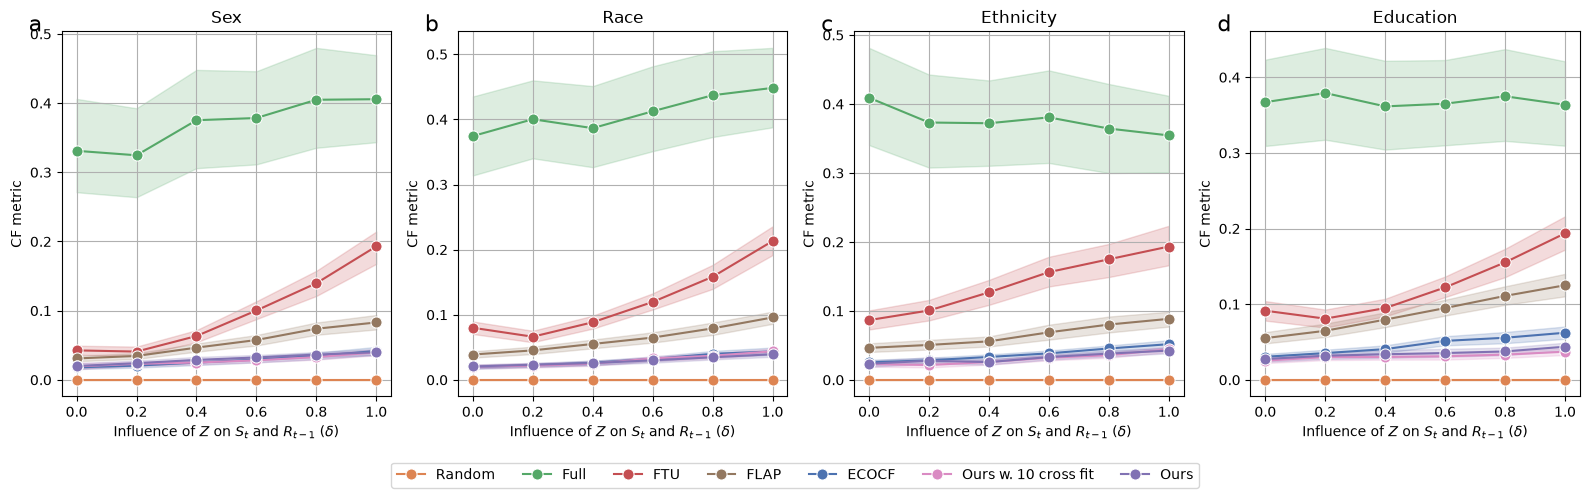

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for var in ["sex", "race", "ethnicity", "education"]:
    plot(var, axs[["sex", "race", "ethnicity", "education"].index(var)])

# Legend handling
handles, labels = axs[0].get_legend_handles_labels()

# Create the Method legend
legend1 = fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=10,
    frameon=True,
)

# Adjust layout and show the plot
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# add a b c d for each subplots
for ax, c in zip(axs, ["a", "b", "c", "d"]):
    ax.text(-0.1, 1.0, c, transform=ax.transAxes, fontsize=16)

fig.savefig("../figures/semi_combined_plots.png", dpi=300, bbox_inches="tight")